# Air Quality Analysis of Indian Cities: Visualization
**Question:** Where and when is India's air worst, is it changing, and which pollutants are prominent?
**Data:** Cleaned India AQI dataset, 235,785 rows (Apr 2022 – Apr 2025). One row = one city on one day.

 Setup

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("aqi_cleaned.csv", parse_dates=["date"])
print(df.shape)

season_order = ["Winter", "Post-Monsoon", "Summer", "Monsoon"]
month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
cat_order = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]

# Cities with at least 300 days of data in each financial year (fair comparison over time)
fy = df[(df["date"] >= "2022-04-01") & (df["date"] <= "2025-03-31")].copy()
fy["period"] = np.where(fy["date"] <= "2023-03-31", "FY2022-23",
                np.where(fy["date"] <= "2024-03-31", "FY2023-24", "FY2024-25"))
days = fy.groupby(["location", "period"]).size().unstack()
stable = days[(days >= 300).all(axis=1)].index
print("Cities with full data in all 3 years:", len(stable))

(235785, 24)
Cities with full data in all 3 years: 95


1. Top 10 Most polluted cities (problem 1)

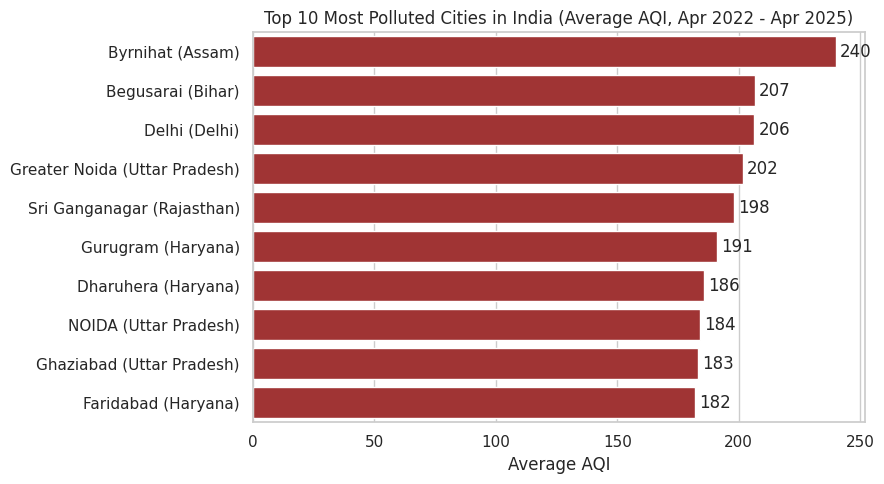

In [3]:
city = df.groupby("location")["aqi_value"].agg(["mean", "count"])
city = city[city["count"] >= 300].sort_values("mean", ascending=False).head(10)

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=city["mean"].values, y=city.index, color="firebrick")
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
plt.title("Top 10 Most Polluted Cities in India (Average AQI, Apr 2022 - Apr 2025)")
plt.xlabel("Average AQI")
plt.ylabel("")
plt.tight_layout()
plt.savefig("v1_top10_cities.png", dpi=150, bbox_inches="tight")
plt.show()

Month × year heatmap (problems 4 and 5)
2. Seasonality and change over the years

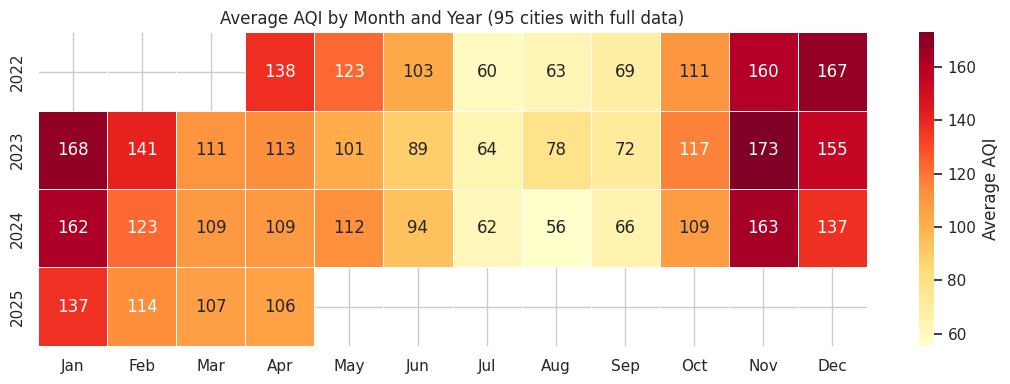

In [4]:
st = df[df["location"].isin(stable)]
heat = st.pivot_table(index="year", columns="month", values="aqi_value", aggfunc="mean")
heat.columns = [month_order[m - 1] for m in heat.columns]
heat = heat.reindex(columns=month_order)

plt.figure(figsize=(11, 4))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="YlOrRd", linewidths=0.5,
            cbar_kws={"label": "Average AQI"})
plt.title("Average AQI by Month and Year (95 cities with full data)")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.savefig("v2_month_year_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

AQI categories by season (problems 3 and 6)
3. How bad are the bad days

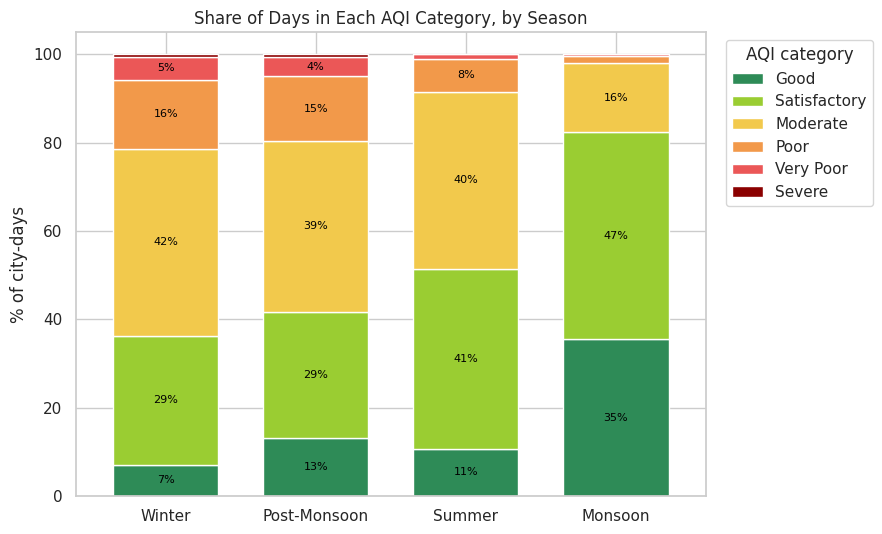

In [5]:
share = pd.crosstab(df["season"], df["aqi_category"], normalize="index") * 100
share = share.reindex(index=season_order, columns=cat_order)

colors = ["#2e8b57", "#9acd32", "#f2c94c", "#f2994a", "#eb5757", "#8b0000"]
ax = share.plot(kind="bar", stacked=True, figsize=(9, 5.5), color=colors, width=0.7)
for c in ax.containers:
    labels = [f"{v:.0f}%" if v >= 4 else "" for v in c.datavalues]
    ax.bar_label(c, labels=labels, label_type="center", fontsize=8, color="black")
plt.title("Share of Days in Each AQI Category, by Season")
plt.xlabel("")
plt.ylabel("% of city-days")
plt.xticks(rotation=0)
plt.legend(title="AQI category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("v3_category_by_season.png", dpi=150, bbox_inches="tight")
plt.show()

Spread of AQI in the six metros (problem 9)
4. How much does AQI vary? (six metros)

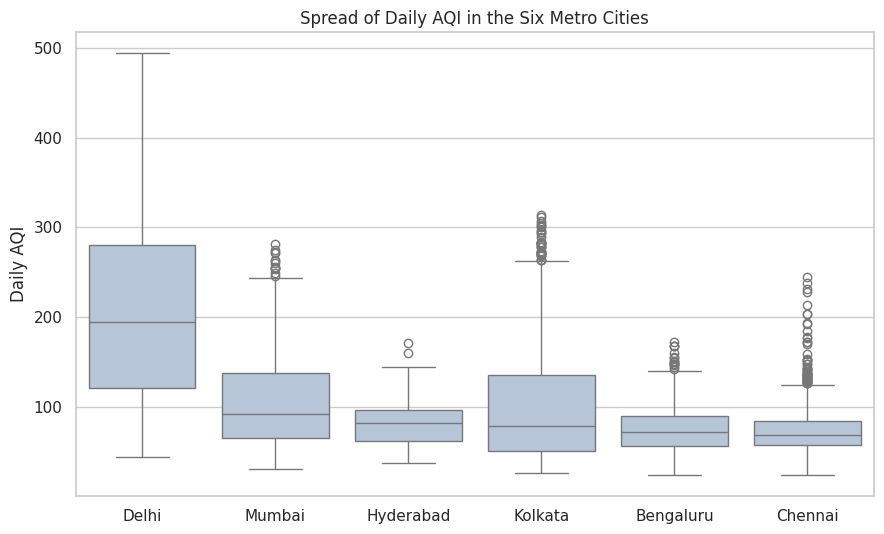

In [6]:
metros = ["Delhi (Delhi)", "Mumbai (Maharashtra)", "Kolkata (West Bengal)",
          "Hyderabad (Telangana)", "Bengaluru (Karnataka)", "Chennai (Tamil Nadu)"]
m = df[df["location"].isin(metros)].copy()
m["city"] = m["location"].str.split(" \\(").str[0]
city_order = m.groupby("city")["aqi_value"].median().sort_values(ascending=False).index

plt.figure(figsize=(9, 5.5))
sns.boxplot(data=m, x="city", y="aqi_value", order=city_order, color="lightsteelblue")
plt.title("Spread of Daily AQI in the Six Metro Cities")
plt.xlabel("")
plt.ylabel("Daily AQI")
plt.tight_layout()
plt.savefig("v4_metro_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

Delhi-NCR versus the rest over time (problem 8)
5. Delhi-NCR vs rest of India, week by week

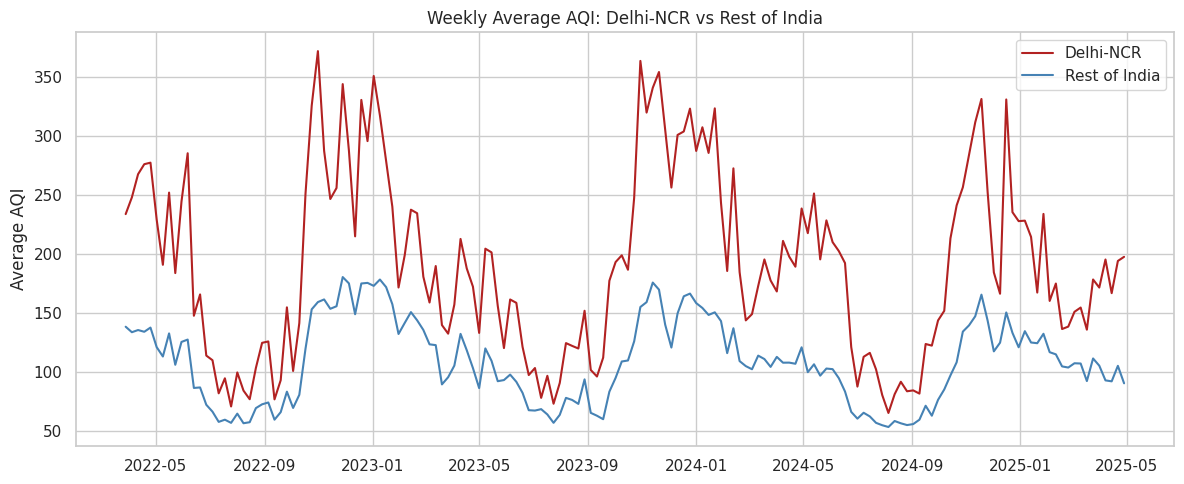

In [7]:
ncr = ["Delhi (Delhi)", "NOIDA (Uttar Pradesh)", "Greater Noida (Uttar Pradesh)",
       "Ghaziabad (Uttar Pradesh)", "Gurugram (Haryana)", "Faridabad (Haryana)"]
df["region"] = np.where(df["location"].isin(ncr), "Delhi-NCR", "Rest of India")
df["week"] = df["date"].dt.to_period("W").dt.start_time

weekly = df.groupby(["week", "region"])["aqi_value"].mean().reset_index()

plt.figure(figsize=(12, 5))
sns.lineplot(data=weekly, x="week", y="aqi_value", hue="region",
             palette={"Delhi-NCR": "firebrick", "Rest of India": "steelblue"})
plt.title("Weekly Average AQI: Delhi-NCR vs Rest of India")
plt.xlabel("")
plt.ylabel("Average AQI")
plt.legend(title="")
plt.tight_layout()
plt.savefig("v5_ncr_weekly.png", dpi=150, bbox_inches="tight")
plt.show()

Pollutants by season (problem 7)
6. Which pollutant is prominent, and when?

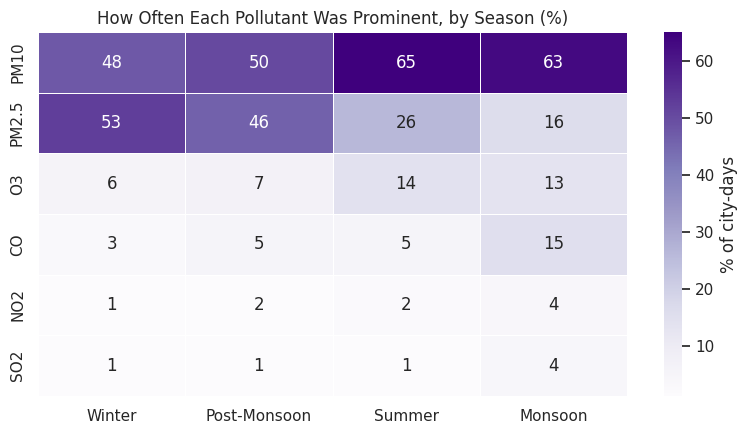

In [8]:
flag_names = {"prom_pm10": "PM10", "prom_pm25": "PM2.5", "prom_o3": "O3",
              "prom_co": "CO", "prom_no2": "NO2", "prom_so2": "SO2"}

pol = (df.groupby("season")[list(flag_names)].mean() * 100).T
pol = pol.rename(index=flag_names)[season_order]

plt.figure(figsize=(8, 4.5))
sns.heatmap(pol, annot=True, fmt=".0f", cmap="Purples", linewidths=0.5,
            cbar_kws={"label": "% of city-days"})
plt.title("How Often Each Pollutant Was Prominent, by Season (%)")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.savefig("v6_pollutants_season.png", dpi=150, bbox_inches="tight")
plt.show()

Is the air improving? (problem 5)
7. Trend over time

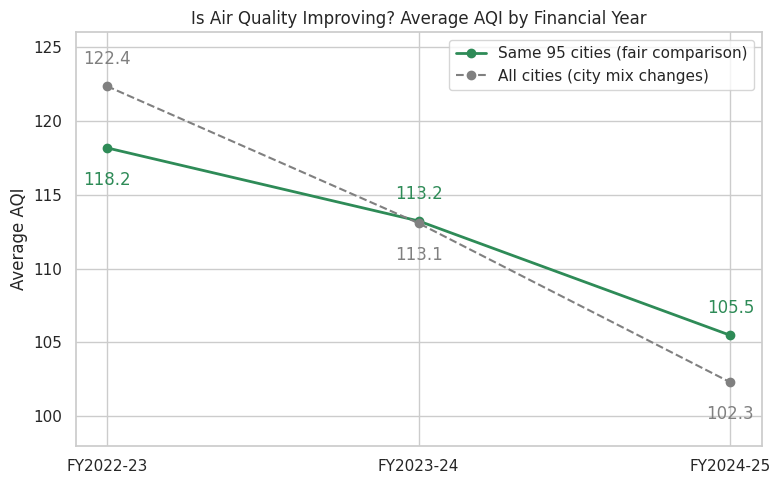

In [9]:
same = fy[fy["location"].isin(stable)].groupby("period")["aqi_value"].mean()
allc = fy.groupby("period")["aqi_value"].mean()

plt.figure(figsize=(8, 5))
plt.plot(same.index, same.values, marker="o", linewidth=2, color="seagreen",
         label=f"Same {len(stable)} cities (fair comparison)")
plt.plot(allc.index, allc.values, marker="o", linestyle="--", color="gray",
         label="All cities (city mix changes)")
for i in range(len(same)):
    s_v, a_v = same.values[i], allc.values[i]
    s_up = s_v >= a_v
    plt.text(i, s_v + (1.5 if s_up else -2.5), f"{s_v:.1f}", ha="center", color="seagreen")
    plt.text(i, a_v + (-2.5 if s_up else 1.5), f"{a_v:.1f}", ha="center", color="gray")
plt.ylim(98, 126)
plt.title("Is Air Quality Improving? Average AQI by Financial Year")
plt.ylabel("Average AQI")
plt.xlabel("")
plt.legend()
plt.tight_layout()
plt.savefig("v7_trend.png", dpi=150, bbox_inches="tight")
plt.show()

Which cities improved or got worse? (problem 5)
8. Biggest improvers and decliners

Improved: 76 | Got worse: 19


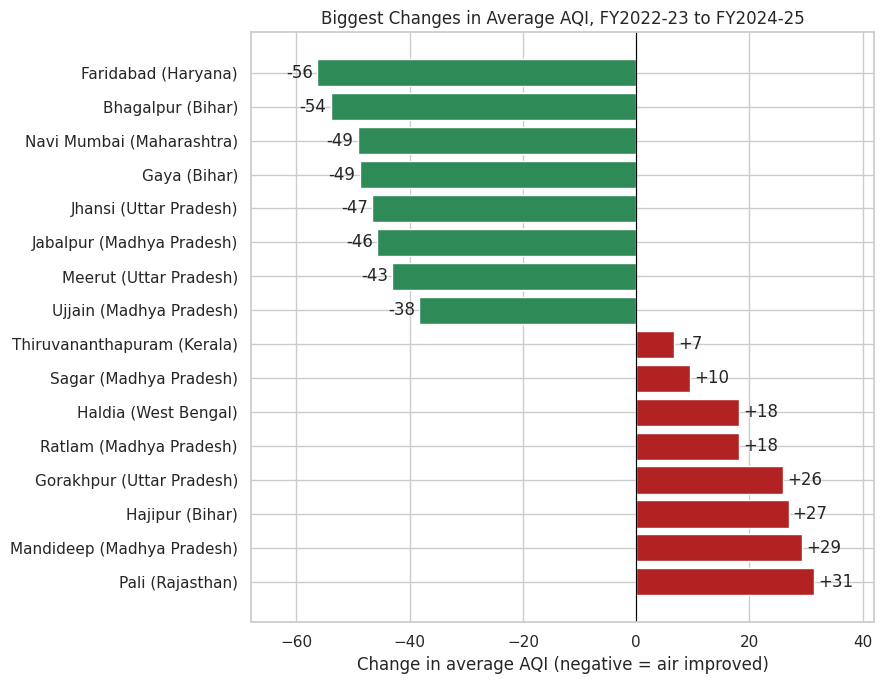

In [10]:
per = fy[fy["location"].isin(stable)].groupby(["location", "period"])["aqi_value"].mean().unstack()
per["change"] = per["FY2024-25"] - per["FY2022-23"]
per = per.sort_values("change")
print("Improved:", int((per["change"] < 0).sum()), "| Got worse:", int((per["change"] > 0).sum()))

both = pd.concat([per.head(8), per.tail(8)])
bar_colors = ["seagreen" if v < 0 else "firebrick" for v in both["change"]]

plt.figure(figsize=(9, 7))
bars = plt.barh(both.index, both["change"], color=bar_colors)
plt.bar_label(bars, fmt="%+.0f", padding=3)
plt.gca().invert_yaxis()
plt.axvline(0, color="black", linewidth=0.8)
plt.xlim(-68, 42)
plt.title("Biggest Changes in Average AQI, FY2022-23 to FY2024-25")
plt.xlabel("Change in average AQI (negative = air improved)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("v8_improvers_decliners.png", dpi=150, bbox_inches="tight")
plt.show()

Severe days (problem 10)
9. The most extreme days (AQI 401 and above)

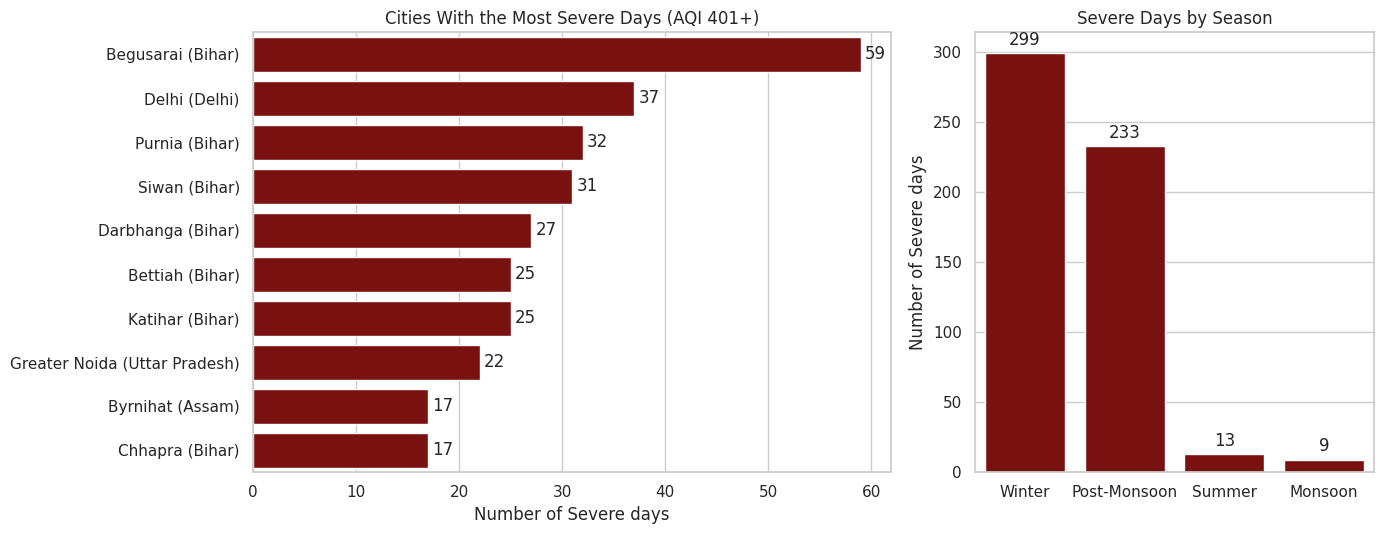

In [11]:
sev = df[df["aqi_category"] == "Severe"]

sc = (sev.groupby("location").size().reset_index(name="severe_days")
         .sort_values(["severe_days", "location"], ascending=[False, True]).head(10))
ss = sev.groupby("season").size().reindex(season_order)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.6, 1]})

sns.barplot(data=sc, x="severe_days", y="location", color="darkred", ax=axes[0])
axes[0].bar_label(axes[0].containers[0], padding=3)
axes[0].set_title("Cities With the Most Severe Days (AQI 401+)")
axes[0].set_xlabel("Number of Severe days")
axes[0].set_ylabel("")

sns.barplot(x=ss.index, y=ss.values, color="darkred", ax=axes[1])
axes[1].bar_label(axes[1].containers[0], padding=3)
axes[1].set_title("Severe Days by Season")
axes[1].set_xlabel("")
axes[1].set_ylabel("Number of Severe days")

plt.tight_layout()
plt.savefig("v9_severe_days.png", dpi=150, bbox_inches="tight")
plt.show()

## Key findings
1. Delhi-NCR cities, plus Byrnihat (Assam), Begusarai (Bihar) and Sri Ganganagar (Rajasthan), have the highest average AQI.
2. Winter and Post-Monsoon are the worst seasons. Monsoon is the cleanest, with 35% of its days rated Good.
3. November is the worst month on average, and July is the cleanest.
4. For the 95 cities with full data, average AQI fell from 118.2 (FY2022-23) to 105.5 (FY2024-25). 76 cities improved and 19 got worse.
5. PM2.5 is most prominent in winter, and PM10 dominates in summer and monsoon.
6. Delhi's daily AQI varies far more than any other metro's, and Bengaluru and Chennai stay steady.
7. Severe days (AQI 401+) are concentrated in winter and post-monsoon. Bihar cities have the most, and Delhi is second.

Limits: the data shows where and when, not why. Coverage grew over time, so trends use only cities with full data. 2022 and 2025 are partial years.

Delhi-NCR also shows short spikes in some summer weeks (May to June 2022, May 2024), though its biggest peaks come in Oct to Nov.